# HW2 – Final pipeline 2. Long RT-DETR runs

RT-DETR-L reached mAP 0.282 in only 4 epochs and was still improving (notebook 05). Here it is trained for 6 h at two input sizes, with the three data changes chosen in `01_data_tests` (masked ignore regions, low-resolution simulation, mosaic at 0.5):

- **960 px:** about 19 epochs.
- **1280 px:** about 11 epochs, with larger objects.

The better run goes on to the train + val retraining and the ensemble.

## 0. Setup

In [7]:
# Make the repo importable: Kaggle clones it, locally the root is two levels above notebooks/final_pipeline/
import os, sys
from pathlib import Path
if os.path.exists("/kaggle/working"):
    if not os.path.exists("/kaggle/working/repo"):
        !git clone --depth 1 https://github.com/BohdanZasymovych/ai-hw2-object-detection.git /kaggle/working/repo
    !pip install -q pycocotools huggingface_hub kaggle ultralytics==8.4.207   # only if missing; torch/torchvision stay Kaggle's own CUDA builds
    ROOT_DIR = Path("/kaggle/working/repo")
else:
    ROOT_DIR = Path.cwd().parents[1] if Path.cwd().parent.name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR))

In [8]:
# Live reload of utils/common.py when editing locally (Kaggle's IPython autoreload is broken on Python 3.13)
if not os.path.exists("/kaggle/working"):
    %load_ext autoreload
    %autoreload 2
import json
import numpy as np
import pandas as pd
import torch
import ultralytics
from utils.common import *
from utils.ultra import ULTRA_VERSION, YOLO_DATA_DIR, export_yolo, load_ultra, train_runs, ultra_predictor

seed_everything()
print(env_info(), "| ultralytics:", ultralytics.__version__, "| data:", RAW_DIR)
if ultralytics.__version__ != ULTRA_VERSION:
    print(f"Warning: tested with ultralytics {ULTRA_VERSION}; the patches in utils/ultra.py depend on its internals")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
{'python': '3.14.4', 'torch': '2.15.0+cu132', 'torchvision': '0.29.2+cu132', 'gpu': 'NVIDIA GeForce RTX 2050', 'on_kaggle': False} | ultralytics: 8.4.207 | data: /home/bohdan/code/ai/hw2-object-detection/data/raw


In [ ]:
QUICK = False                                    # True: local smoke test (few frames, 1 epoch, small input, nothing pushed)
ALL_STAGES = {"960", "1280"}
RUN = ALL_STAGES if os.path.exists("/kaggle/working") or QUICK else set()   # stages computed in this session; the rest are pulled from the HF repo
USED = {"ignore", "lowres", "mosaic"}            # data changes chosen in 01_data_tests; a subset of these, or set() for none
SUBMIT = False                 # True: write the test predictions of the better run and submit them to Kaggle

# Fail early if the results could not be uploaded or submitted
if RUN and not QUICK:
    check_hf_write()
if SUBMIT and ON_KAGGLE:
    kaggle_secrets()

## 1. Training setup

Same as `rtdetr_lr` in notebook 05 (AdamW, lr 1e-4, backbone lr ×0.1, 100 denoising queries, batch 4, nominal batch 16), except for:

- **Budget:** 6 h per run. The learning rate decays until the budget ends.
- **Mosaic off for the last 2 epochs** instead of 1, so that the model finishes on normal frames.

In [10]:
CFG = dict(
    arch="rtdetr-l", weights="rtdetr-l.pt", long_side=640 if QUICK else PREP["long_side"],
    train_frames=16 if QUICK else None, val_frames=8 if QUICK else None, num_workers=4, seed=SEED,
    train=dict(  # Ultralytics train() arguments shared by both runs
        batch=2 if QUICK else 4, epochs=1 if QUICK else 100, time=None if QUICK else 6, optimizer="AdamW",
        lr0=1e-4, weight_decay=1e-4, nbs=16, warmup_epochs=0 if QUICK else 0.5, warmup_bias_lr=0.0,
        close_mosaic=0 if QUICK else 2, scale=0.25, workers=2 if QUICK else 4, seed=SEED, deterministic=False,
        max_det=EVAL_DETS, plots=False, cache=False),
)
MODEL = dict(backbone_lr_ratio=0.1, nd=100)
INPUT = {"960": 320, "1280": 480} if QUICK else {"960": 960, "1280": 1280}                  # training input of each run
GRID = {"960": [320], "1280": [320, 480]} if QUICK else {"960": [960, 1120, 1280], "1280": [1120, 1280, 1440]}   # test inputs
LOW_SIDES = (480, 320) if QUICK else (960, 680)     # low resolutions of the low-resolution simulation, as in 01_data_tests


def name(stage):
    return f"s2_{stage}" + ("_quick" if QUICK else "")


def load_preds(run):
    return json.load(open(fetch_run(run) / "preds_val.json"))

## 2. Data changes

The three changes chosen in `01_data_tests`, all applied to the training frames only. Masked ignore regions and low-resolution simulation are applied in the data export; mosaic at 0.5 is a training argument (section 3). The val frames stay unchanged, so every run is evaluated on the same frames.

In [11]:
val_ids = DetDataset("val", max_frames=CFG["val_frames"]).image_ids
val_frames = subsample(load_split("val")[0])
val_frames = val_frames[val_frames.image_id.isin(val_ids)]
test_like = val_frames[val_frames.width <= 1920].image_id.tolist()     # val frames of sizes that occur in the test set
print("data changes used:", sorted(USED) or "none")

data changes used: ['ignore', 'lowres', 'mosaic']


## 3. Long runs

In [12]:
def dataset():
    # Data yaml with the selected data changes; without any, the standard dataset of notebook 05
    changes = sorted(USED & {"ignore", "lowres"})
    folder = "_".join((["quick"] if QUICK else [str(CFG["long_side"])]) + changes)
    return export_yolo(YOLO_DATA_DIR / folder, long_side=CFG["long_side"], max_frames=CFG["train_frames"], mask_ignore="ignore" in USED,
                       lowres={s: 0.1 for s in LOW_SIDES} if "lowres" in USED else None)


def predict_val(model, imgsz):
    ds = DetDataset("val", label_offset=0, max_frames=CFG["val_frames"], long_side=max(CFG["long_side"], imgsz))
    return predict_dataset(ultra_predictor(model, imgsz), ds, batch_size=1, num_workers=CFG["num_workers"])


def evaluate_run(stage):
    # The best test input of a trained run, by val mAP; its predictions are saved
    model = load_ultra(run_dir(name(stage)) / "best.pt")
    rows, best = {}, None
    for sz in GRID[stage]:
        preds, ms = predict_val(model, sz)
        m = {**coco_evaluate(preds, "val", image_ids=val_ids), "ms_per_img": ms}
        rows[sz] = {k: v for k, v in m.items() if k != "per_class"}
        if best is None or m["mAP"] > best[1]["mAP"]:
            best = (sz, m, preds)
    d = save_run(name(stage), config={**CFG, "model": MODEL, "used": sorted(USED), "input": INPUT[stage], "test": dict(imgsz=best[0]),
                                      "image_ids": val_ids}, metrics=best[1], preds=best[2])
    pd.DataFrame(rows).T.rename_axis("imgsz").to_csv(d / "grid.csv")
    if not QUICK:
        push_run(name(stage))
    del model
    torch.cuda.empty_cache()


stages = sorted(RUN, key=int)
if stages:
    overrides = dict(mosaic=0.5) if "mosaic" in USED else {}
    data = str(dataset())
    train_runs([dict(name=name(s), data=data, arch=CFG["arch"], weights=CFG["weights"], **MODEL,
                     train={**CFG["train"], **overrides, "imgsz": INPUT[s]}) for s in stages], checkpoint_min=None if QUICK else 30)
    for s in stages:
        evaluate_run(s)

## 4. Comparison

All rows use the same val frames and evaluation as `01_data_tests`. The reference is `rtdetr_final` from notebook 05 (1280 px): val mAP 0.282, AP_small 0.137, shown as a fixed number so this notebook needs no earlier results. Test-like mAP leaves out the val frames wider than 1920 px, which do not occur in the test set. The better run is the one with the higher mAP; if the two are within 0.005, the one with the higher test-like mAP.

In [13]:
BASELINE_MAP = 0.2819                            # rtdetr_final (notebook 05), val mAP at 1280 px


def row(preds):
    m = coco_evaluate(preds, "val", image_ids=val_ids)
    return {"mAP": m["mAP"], "Δ mAP vs rtdetr_final": m["mAP"] - BASELINE_MAP, "AP50": m["AP50"], "AP_small": m["AP_small"],
            "AR": m["AR"], "test-like mAP": coco_evaluate(preds, "val", image_ids=test_like)["mAP"]}


def label(stage):
    return f"{stage} px, tested at {json.load(open(fetch_run(name(stage)) / 'config.json'))['test']['imgsz']} px"


preds = {s: load_preds(name(s)) for s in INPUT}
scores = {s: row(preds[s]) for s in INPUT}
a, b = list(INPUT)
if abs(scores[a]["mAP"] - scores[b]["mAP"]) < 0.005:
    winner = max(INPUT, key=lambda s: scores[s]["test-like mAP"])
else:
    winner = max(INPUT, key=lambda s: scores[s]["mAP"])
print("better run:", label(winner))
table = pd.DataFrame({**{label(s): scores[s] for s in INPUT}, "WBF: both long runs": row(wbf(list(preds.values())))}).T
table.sort_values("Δ mAP vs rtdetr_final", ascending=False).round(3)

/home/bohdan/code/ai/hw2-object-detection/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 10 files: 100%|██████████| 10/10 [00:03<00:00,  3.00it/s]


better run: 1280 px, tested at 1440 px


,mAP,Δ mAP vs rtdetr_final,AP50,AP_small,AR,test-like mAP
WBF: both long runs,0.311,0.030,0.569,0.150,0.508,0.313
"1280 px, tested at 1440 px",0.306,0.024,0.566,0.149,0.500,0.310
"960 px, tested at 1280 px",0.299,0.017,0.548,0.150,0.488,0.310


Validation mAP over training (Ultralytics' own, so comparable between these runs only).

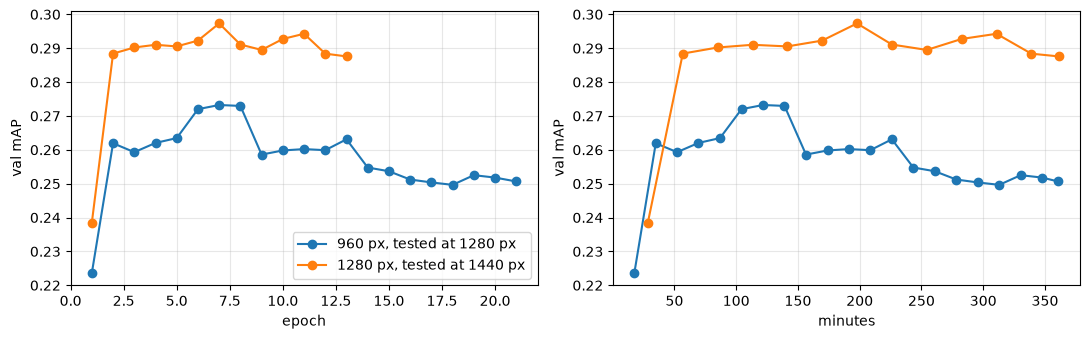

In [14]:
plot_history({label(s): json.load(open(fetch_run(name(s)) / "history.json")) for s in INPUT})

## 5. Submission

Test predictions of the better run, written to `submissions/submission_<run>.csv`, validated against `test_images.csv` and uploaded to Kaggle, for its public score.

In [15]:
if SUBMIT:
    sz = json.load(open(fetch_run(name(winner)) / "config.json"))["test"]["imgsz"]
    model = load_ultra(fetch_run(name(winner), weights=True) / "best.pt")
    path = make_submission(ultra_predictor(model, sz), name(winner), long_side=max(CFG["long_side"], sz), label_offset=0,
                           num_workers=CFG["num_workers"])
    submit_to_kaggle(path, f"RT-DETR-L long run: {label(winner)}, data changes: {sorted(USED) or 'none'}")
    del model
    torch.cuda.empty_cache()

Fetching 12 files: 100%|██████████| 12/12 [00:13<00:00,  1.16s/it]


/home/bohdan/code/ai/hw2-object-detection/submissions/submission_s2_1280.csv: 3811 frames, 1143300 boxes, 135 ms/img, 36 MB
Submitted /home/bohdan/code/ai/hw2-object-detection/submissions/submission_s2_1280.csv: RT-DETR-L long run: 1280 px, tested at 1440 px, data changes: ['ignore', 'lowres', 'mosaic']
status: SubmissionStatus.COMPLETE | public score: 0.3290439089


## 6. Conclusion

Both runs improve on `rtdetr_final` (val mAP 0.282, public 0.2590):

- **1280 px run:** val mAP 0.306 (+0.024), public **0.3290** (+0.070). The better run, and the one submitted.
- **960 px run:** val mAP 0.299 (+0.017).
- **WBF of both runs:** val mAP 0.311 (+0.030).
- **Training length:** both runs peaked at epoch 7 (of 21 and 13) and then overfit, so most of the 6 h was not needed.
- **Test-like frames:** the gain over `rtdetr_final` is smaller (0.310 against 0.300) than on all of val, so part of the val gain is on frames the test set lacks.

The data changes were applied together, so their separate effects are not measured.